In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/competitions/comment-category-prediction-challenge/Sample.csv
/kaggle/input/competitions/comment-category-prediction-challenge/train.csv
/kaggle/input/competitions/comment-category-prediction-challenge/test.csv


# 🏷️ Milestone 4: Ensemble Methods & MLP Neural Network
**Comment Category Prediction Challenge**

**M3 Best Results:** Tuned LinearSVC (C=0.1, balanced) → Accuracy 0.927, Macro F1 0.870 | Kaggle: 0.816

**Key Lessons from M1-M3:**
- Kaggle metric = **Macro F1** (not accuracy)
- `class_weight='balanced'` helps Macro F1 (boosts Label 3 recall)
- Word TF-IDF (15K) + Char n-gram TF-IDF (10K) gives best features
- LinearSVC with C=0.1 is the single-model champion
- Label 3 (2.76% of data) is the hardest class — key to improving score

**This notebook covers:**
1. Milestone 4 Questions (all 9)
2. **Random Forest** (Bagging)
3. **AdaBoost** (Boosting)
4. **XGBoost / LightGBM** (Gradient Boosting)
5. **MLP** (Neural Network)
6. **Voting Ensemble** (combine top models)
7. **Stacking Ensemble** (meta-learner)
8. Final Comparison & Best Submission (targeting 0.90)

⚡ Uses Grandmaster-style precomputed TF-IDF pipeline.
---

## 1. Setup & Imports

In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
import string
import re

from scipy.sparse import hstack, csr_matrix

from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     GridSearchCV, RandomizedSearchCV,
                                     cross_val_score)
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.preprocessing import (StandardScaler, MinMaxScaler,
                                   OneHotEncoder, LabelEncoder)
from sklearn.impute import SimpleImputer
from sklearn.decomposition import TruncatedSVD
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.ensemble import (RandomForestClassifier, AdaBoostClassifier,
                              VotingClassifier, StackingClassifier,
                              BaggingClassifier, GradientBoostingClassifier)
from sklearn.neural_network import MLPClassifier
from sklearn.svm import LinearSVC
from sklearn.linear_model import (LogisticRegression, SGDClassifier,
                                  RidgeClassifier, PassiveAggressiveClassifier)
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.calibration import CalibratedClassifierCV

from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay,
                             f1_score, make_scorer)

import warnings
warnings.filterwarnings("ignore")

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 12
sns.set_style("whitegrid")
sns.set_palette("viridis")

# ════════════════════════════════════════════════════════════
# GPU Auto-Detection: Uses GPU when available, CPU fallback
# ════════════════════════════════════════════════════════════
import subprocess
try:
    subprocess.check_output(["nvidia-smi"])
    HAS_GPU = True
    XGB_DEVICE = "cuda"            # XGBoost 2.0+ uses device param
    LGB_DEVICE = "gpu"
    print("🖥️ GPU DETECTED → XGBoost: cuda | LightGBM: gpu")
except (FileNotFoundError, subprocess.CalledProcessError):
    HAS_GPU = False
    XGB_DEVICE = "cpu"
    LGB_DEVICE = "cpu"
    print("💻 No GPU found → Using CPU (all cores via n_jobs=-1)")

print("✅ All libraries imported successfully.")




🖥️ GPU DETECTED → XGBoost: cuda | LightGBM: gpu
✅ All libraries imported successfully.


## 2. Data Loading

In [3]:
train = pd.read_csv("/kaggle/input/competitions/comment-category-prediction-challenge/train.csv")
test  = pd.read_csv("/kaggle/input/competitions/comment-category-prediction-challenge/test.csv")
sample = pd.read_csv("/kaggle/input/competitions/comment-category-prediction-challenge/Sample.csv")

print(f"Train: {train.shape} | Test: {test.shape} | Sample: {sample.shape}")

# Fill NaN comments with empty strings (required for M4 questions)
train["comment"] = train["comment"].fillna("")
test["comment"] = test["comment"].fillna("")

print(f"✅ Data loaded. Train: {train.shape} | Test: {test.shape}")


Train: (198000, 15) | Test: (102000, 14) | Sample: (102000, 2)
✅ Data loaded. Train: (198000, 15) | Test: (102000, 14)


## 3. Milestone 4 Questions
These questions use specific preprocessing as prescribed.


In [4]:
"""
# ──────────────────────────────────────────────────────────
# 📌 M4 Q1: Two train-validation splits (60/40, random_state=2306)
# Part A: stratify=y, Part B: stratify=None
# Compute max absolute difference between validation proportions
# ──────────────────────────────────────────────────────────

X = train.drop(columns=["label"])
y = train["label"]

# Part A: Stratified
X_train_a, X_val_a, y_train_a, y_val_a = train_test_split(
    X, y, test_size=0.4, random_state=2306, stratify=y
)

# Part B: Non-stratified
X_train_b, X_val_b, y_train_b, y_val_b = train_test_split(
    X, y, test_size=0.4, random_state=2306, stratify=None
)

# Sorted class-wise counts
print("=== Part A (Stratified) ===")
print("Train counts:", y_train_a.value_counts().sort_index().values)
print("Val counts:  ", y_val_a.value_counts().sort_index().values)

print("\n=== Part B (Non-stratified) ===")
print("Train counts:", y_train_b.value_counts().sort_index().values)
print("Val counts:  ", y_val_b.value_counts().sort_index().values)

# Validation proportions
val_prop_strat = y_val_a.value_counts().sort_index() / len(y_val_a)
val_prop_nostrat = y_val_b.value_counts().sort_index() / len(y_val_b)

abs_diff = (val_prop_strat - val_prop_nostrat).abs()
max_abs_diff = abs_diff.max()

print(f"\nStratified val proportions:     {val_prop_strat.values}")
print(f"Non-stratified val proportions: {val_prop_nostrat.values}")
print(f"Absolute differences:           {abs_diff.values}")
print(f"\n→ ANSWER Q1: Max absolute difference = {max_abs_diff:.6f}")
"""

'\n# ──────────────────────────────────────────────────────────\n# 📌 M4 Q1: Two train-validation splits (60/40, random_state=2306)\n# Part A: stratify=y, Part B: stratify=None\n# Compute max absolute difference between validation proportions\n# ──────────────────────────────────────────────────────────\n\nX = train.drop(columns=["label"])\ny = train["label"]\n\n# Part A: Stratified\nX_train_a, X_val_a, y_train_a, y_val_a = train_test_split(\n    X, y, test_size=0.4, random_state=2306, stratify=y\n)\n\n# Part B: Non-stratified\nX_train_b, X_val_b, y_train_b, y_val_b = train_test_split(\n    X, y, test_size=0.4, random_state=2306, stratify=None\n)\n\n# Sorted class-wise counts\nprint("=== Part A (Stratified) ===")\nprint("Train counts:", y_train_a.value_counts().sort_index().values)\nprint("Val counts:  ", y_val_a.value_counts().sort_index().values)\n\nprint("\n=== Part B (Non-stratified) ===")\nprint("Train counts:", y_train_b.value_counts().sort_index().values)\nprint("Val counts:  ", 

In [5]:
"""
# ──────────────────────────────────────────────────────────
# 📌 M4 Q2: Full preprocessing with ColumnTransformer + TF-IDF + hstack
# Sum of all values in X_train_final, rounded to 3 decimal places
# ──────────────────────────────────────────────────────────

# Use stratified split from Q1
X_train_q2 = X_train_a.copy()
X_val_q2   = X_val_a.copy()

# Drop created_date
X_train_q2 = X_train_q2.drop(columns=["created_date"])
X_val_q2   = X_val_q2.drop(columns=["created_date"])

# Separate comment as text
text_train_q2 = X_train_q2["comment"].astype(str)
text_val_q2   = X_val_q2["comment"].astype(str)

# Remove comment from tabular
X_train_tab = X_train_q2.drop(columns=["comment"])
X_val_tab   = X_val_q2.drop(columns=["comment"])

# Define columns
cat_cols_q2 = ["race", "religion", "gender", "disability"]
num_cols_q2 = ["post_id", "emoticon_1", "emoticon_2", "emoticon_3",
               "upvote", "downvote", "if_1", "if_2"]

# ColumnTransformer
preprocessor_q2 = ColumnTransformer(
    transformers=[
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=True))
        ]), cat_cols_q2),
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="mean")),
            ("scaler", StandardScaler())
        ]), num_cols_q2),
    ],
    remainder="passthrough"
)

X_train_tabular = preprocessor_q2.fit_transform(X_train_tab)
X_val_tabular   = preprocessor_q2.transform(X_val_tab)

# normalize_text function
def normalize_text(text):
    text = text.lower()
    text = re.sub(r"[^\w\s]", "", text)  # Remove punctuation
    text = text.strip()
    return text

text_train_norm = text_train_q2.apply(normalize_text)
text_val_norm   = text_val_q2.apply(normalize_text)

# TF-IDF
tfidf_q2 = TfidfVectorizer(stop_words="english", max_features=5000)
X_train_tfidf_q2 = tfidf_q2.fit_transform(text_train_norm)
X_val_tfidf_q2   = tfidf_q2.transform(text_val_norm)

# Combine: tabular + TF-IDF (in specified order)
X_train_final_q2 = hstack([X_train_tabular, X_train_tfidf_q2])
X_val_final_q2   = hstack([X_val_tabular, X_val_tfidf_q2])

sum_train_final = X_train_final_q2.sum()
print(f"🔹 X_train_final shape: {X_train_final_q2.shape}")
print(f"🔹 Sum of all values: {sum_train_final}")
print(f"\n→ ANSWER Q2: Sum = {sum_train_final:.3f}")
"""

'\n# ──────────────────────────────────────────────────────────\n# 📌 M4 Q2: Full preprocessing with ColumnTransformer + TF-IDF + hstack\n# Sum of all values in X_train_final, rounded to 3 decimal places\n# ──────────────────────────────────────────────────────────\n\n# Use stratified split from Q1\nX_train_q2 = X_train_a.copy()\nX_val_q2   = X_val_a.copy()\n\n# Drop created_date\nX_train_q2 = X_train_q2.drop(columns=["created_date"])\nX_val_q2   = X_val_q2.drop(columns=["created_date"])\n\n# Separate comment as text\ntext_train_q2 = X_train_q2["comment"].astype(str)\ntext_val_q2   = X_val_q2["comment"].astype(str)\n\n# Remove comment from tabular\nX_train_tab = X_train_q2.drop(columns=["comment"])\nX_val_tab   = X_val_q2.drop(columns=["comment"])\n\n# Define columns\ncat_cols_q2 = ["race", "religion", "gender", "disability"]\nnum_cols_q2 = ["post_id", "emoticon_1", "emoticon_2", "emoticon_3",\n               "upvote", "downvote", "if_1", "if_2"]\n\n# ColumnTransformer\npreprocessor_q2 

In [6]:
"""
# ──────────────────────────────────────────────────────────
# 📌 M4 Q3: TruncatedSVD + RandomizedSearchCV for RandomForest
# Return best n_estimators
# ──────────────────────────────────────────────────────────

svd_q3 = TruncatedSVD(n_components=300, random_state=2306)
X_train_reduced = svd_q3.fit_transform(X_train_final_q2)
X_val_reduced   = svd_q3.transform(X_val_final_q2)

print(f"🔹 X_train_reduced shape: {X_train_reduced.shape}")

param_dist_rf = {
    "n_estimators": [50, 100, 200],
    "max_depth": [5, 10, 15],
}

rcv_rf = RandomizedSearchCV(
    RandomForestClassifier(random_state=2306),
    param_distributions=param_dist_rf,
    n_iter=5, cv=3, random_state=2306, n_jobs=-1, verbose=1
)
rcv_rf.fit(X_train_reduced, y_train_a)

print(f"\n🔹 Best params: {rcv_rf.best_params_}")
print(f"🔹 Best score: {rcv_rf.best_score_:.4f}")
print(f"\n→ ANSWER Q3: Best n_estimators = {rcv_rf.best_params_['n_estimators']}")
"""

'\n# ──────────────────────────────────────────────────────────\n# 📌 M4 Q3: TruncatedSVD + RandomizedSearchCV for RandomForest\n# Return best n_estimators\n# ──────────────────────────────────────────────────────────\n\nsvd_q3 = TruncatedSVD(n_components=300, random_state=2306)\nX_train_reduced = svd_q3.fit_transform(X_train_final_q2)\nX_val_reduced   = svd_q3.transform(X_val_final_q2)\n\nprint(f"🔹 X_train_reduced shape: {X_train_reduced.shape}")\n\nparam_dist_rf = {\n    "n_estimators": [50, 100, 200],\n    "max_depth": [5, 10, 15],\n}\n\nrcv_rf = RandomizedSearchCV(\n    RandomForestClassifier(random_state=2306),\n    param_distributions=param_dist_rf,\n    n_iter=5, cv=3, random_state=2306, n_jobs=-1, verbose=1\n)\nrcv_rf.fit(X_train_reduced, y_train_a)\n\nprint(f"\n🔹 Best params: {rcv_rf.best_params_}")\nprint(f"🔹 Best score: {rcv_rf.best_score_:.4f}")\nprint(f"\n→ ANSWER Q3: Best n_estimators = {rcv_rf.best_params_[\'n_estimators\']}")\n'

In [7]:
"""
# ──────────────────────────────────────────────────────────
# 📌 M4 Q4: AdaBoost variance of estimator errors
# ──────────────────────────────────────────────────────────

ada = AdaBoostClassifier(n_estimators=50, random_state=2306)
ada.fit(X_train_reduced, y_train_a)

variance_errors = np.var(ada.estimator_errors_)
print(f"🔹 Estimator errors: {ada.estimator_errors_[:10]}... (first 10)")
print(f"🔹 Variance of estimator_errors_: {variance_errors}")
print(f"\n→ ANSWER Q4: Variance = {variance_errors:.4f}")
"""

'\n# ──────────────────────────────────────────────────────────\n# 📌 M4 Q4: AdaBoost variance of estimator errors\n# ──────────────────────────────────────────────────────────\n\nada = AdaBoostClassifier(n_estimators=50, random_state=2306)\nada.fit(X_train_reduced, y_train_a)\n\nvariance_errors = np.var(ada.estimator_errors_)\nprint(f"🔹 Estimator errors: {ada.estimator_errors_[:10]}... (first 10)")\nprint(f"🔹 Variance of estimator_errors_: {variance_errors}")\nprint(f"\n→ ANSWER Q4: Variance = {variance_errors:.4f}")\n'

In [8]:
"""
# ──────────────────────────────────────────────────────────
# 📌 M4 Q5: RandomForest feature importance — index of max
# ──────────────────────────────────────────────────────────

rf_q5 = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=2306)
rf_q5.fit(X_train_reduced, y_train_a)

importances = rf_q5.feature_importances_
max_imp_idx = np.argmin(-importances)  # argmax equivalent, returns smallest index if tied
# Verify with argmax
max_imp_idx = int(np.argmax(importances))

print(f"🔹 Feature importances shape: {importances.shape}")
print(f"🔹 Top 5 importance values: {np.sort(importances)[-5:][::-1]}")
print(f"🔹 Index of max importance: {max_imp_idx}")
print(f"🔹 Max importance value: {importances[max_imp_idx]:.6f}")
print(f"\n→ ANSWER Q5: Index of max importance = {max_imp_idx}")
"""

'\n# ──────────────────────────────────────────────────────────\n# 📌 M4 Q5: RandomForest feature importance — index of max\n# ──────────────────────────────────────────────────────────\n\nrf_q5 = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=2306)\nrf_q5.fit(X_train_reduced, y_train_a)\n\nimportances = rf_q5.feature_importances_\nmax_imp_idx = np.argmin(-importances)  # argmax equivalent, returns smallest index if tied\n# Verify with argmax\nmax_imp_idx = int(np.argmax(importances))\n\nprint(f"🔹 Feature importances shape: {importances.shape}")\nprint(f"🔹 Top 5 importance values: {np.sort(importances)[-5:][::-1]}")\nprint(f"🔹 Index of max importance: {max_imp_idx}")\nprint(f"🔹 Max importance value: {importances[max_imp_idx]:.6f}")\nprint(f"\n→ ANSWER Q5: Index of max importance = {max_imp_idx}")\n'

In [9]:
"""
# ──────────────────────────────────────────────────────────
# 📌 M4 Q6: MLP weight count (excluding biases)
# Input: N, Hidden: 128, 64, 32, Output: 4
# ──────────────────────────────────────────────────────────

N = X_train_reduced.shape[1]
# Weights = connections between layers (no biases)
weights_layer1 = N * 128        # input → first hidden
weights_layer2 = 128 * 64       # first hidden → second hidden
weights_layer3 = 64 * 32        # second hidden → third hidden
weights_output = 32 * 4         # third hidden → output

total_weights = weights_layer1 + weights_layer2 + weights_layer3 + weights_output

print(f"🔹 Input features (N): {N}")
print(f"🔹 Layer 1 (N×128):    {weights_layer1:,}")
print(f"🔹 Layer 2 (128×64):   {weights_layer2:,}")
print(f"🔹 Layer 3 (64×32):    {weights_layer3:,}")
print(f"🔹 Output (32×4):      {weights_output:,}")
print(f"\n→ ANSWER Q6: Total weights = {total_weights}")
"""

'\n# ──────────────────────────────────────────────────────────\n# 📌 M4 Q6: MLP weight count (excluding biases)\n# Input: N, Hidden: 128, 64, 32, Output: 4\n# ──────────────────────────────────────────────────────────\n\nN = X_train_reduced.shape[1]\n# Weights = connections between layers (no biases)\nweights_layer1 = N * 128        # input → first hidden\nweights_layer2 = 128 * 64       # first hidden → second hidden\nweights_layer3 = 64 * 32        # second hidden → third hidden\nweights_output = 32 * 4         # third hidden → output\n\ntotal_weights = weights_layer1 + weights_layer2 + weights_layer3 + weights_output\n\nprint(f"🔹 Input features (N): {N}")\nprint(f"🔹 Layer 1 (N×128):    {weights_layer1:,}")\nprint(f"🔹 Layer 2 (128×64):   {weights_layer2:,}")\nprint(f"🔹 Layer 3 (64×32):    {weights_layer3:,}")\nprint(f"🔹 Output (32×4):      {weights_output:,}")\nprint(f"\n→ ANSWER Q6: Total weights = {total_weights}")\n'

In [10]:
"""
# ──────────────────────────────────────────────────────────
# 📌 M4 Q7: Train MLP, return final loss rounded to 4 decimal places
# ──────────────────────────────────────────────────────────

mlp_q7 = MLPClassifier(
    hidden_layer_sizes=(128, 64, 32),
    activation="relu",
    solver="adam",
    max_iter=5,
    batch_size=32,
    random_state=2306
)
mlp_q7.fit(X_train_reduced, y_train_a)

final_loss = mlp_q7.loss_
print(f"🔹 Final loss after 5 iterations: {final_loss}")
print(f"\n→ ANSWER Q7: Final loss = {final_loss:.4f}")
"""

'\n# ──────────────────────────────────────────────────────────\n# 📌 M4 Q7: Train MLP, return final loss rounded to 4 decimal places\n# ──────────────────────────────────────────────────────────\n\nmlp_q7 = MLPClassifier(\n    hidden_layer_sizes=(128, 64, 32),\n    activation="relu",\n    solver="adam",\n    max_iter=5,\n    batch_size=32,\n    random_state=2306\n)\nmlp_q7.fit(X_train_reduced, y_train_a)\n\nfinal_loss = mlp_q7.loss_\nprint(f"🔹 Final loss after 5 iterations: {final_loss}")\nprint(f"\n→ ANSWER Q7: Final loss = {final_loss:.4f}")\n'

In [11]:
"""
# ──────────────────────────────────────────────────────────
# 📌 M4 Q8: Two MLPs with different alpha, absolute F1 difference
# ──────────────────────────────────────────────────────────

mlp_a = MLPClassifier(
    hidden_layer_sizes=(100,), max_iter=5, random_state=2306, alpha=0.0001
)
mlp_b = MLPClassifier(
    hidden_layer_sizes=(100,), max_iter=5, random_state=2306, alpha=1.0
)

mlp_a.fit(X_train_reduced, y_train_a)
mlp_b.fit(X_train_reduced, y_train_a)

f1_a = f1_score(y_train_a, mlp_a.predict(X_train_reduced), average="macro")
f1_b = f1_score(y_train_a, mlp_b.predict(X_train_reduced), average="macro")

abs_diff_f1 = abs(f1_a - f1_b)

print(f"🔹 MLP A (alpha=0.0001) Train Macro F1: {f1_a:.4f}")
print(f"🔹 MLP B (alpha=1.0)    Train Macro F1: {f1_b:.4f}")
print(f"\n→ ANSWER Q8: |F1_A - F1_B| = {abs_diff_f1:.4f}")
"""

'\n# ──────────────────────────────────────────────────────────\n# 📌 M4 Q8: Two MLPs with different alpha, absolute F1 difference\n# ──────────────────────────────────────────────────────────\n\nmlp_a = MLPClassifier(\n    hidden_layer_sizes=(100,), max_iter=5, random_state=2306, alpha=0.0001\n)\nmlp_b = MLPClassifier(\n    hidden_layer_sizes=(100,), max_iter=5, random_state=2306, alpha=1.0\n)\n\nmlp_a.fit(X_train_reduced, y_train_a)\nmlp_b.fit(X_train_reduced, y_train_a)\n\nf1_a = f1_score(y_train_a, mlp_a.predict(X_train_reduced), average="macro")\nf1_b = f1_score(y_train_a, mlp_b.predict(X_train_reduced), average="macro")\n\nabs_diff_f1 = abs(f1_a - f1_b)\n\nprint(f"🔹 MLP A (alpha=0.0001) Train Macro F1: {f1_a:.4f}")\nprint(f"🔹 MLP B (alpha=1.0)    Train Macro F1: {f1_b:.4f}")\nprint(f"\n→ ANSWER Q8: |F1_A - F1_B| = {abs_diff_f1:.4f}")\n'

In [12]:
"""
# ──────────────────────────────────────────────────────────
# 📌 M4 Q9: MLP (from Q7) confusion matrix on validation
# Sum of off-diagonal / total samples
# ──────────────────────────────────────────────────────────

y_val_pred_q9 = mlp_q7.predict(X_val_reduced)
cm_q9 = confusion_matrix(y_val_a, y_val_pred_q9)

total_samples = cm_q9.sum()
diagonal_sum = np.trace(cm_q9)
off_diagonal_sum = total_samples - diagonal_sum

result_q9 = off_diagonal_sum / total_samples

print(f"🔹 Confusion Matrix:")
print(cm_q9)
print(f"\n🔹 Total samples: {total_samples}")
print(f"🔹 Diagonal sum (correct): {diagonal_sum}")
print(f"🔹 Off-diagonal sum (errors): {off_diagonal_sum}")
print(f"\n→ ANSWER Q9: Off-diagonal/total = {result_q9:.4f}")
"""

'\n# ──────────────────────────────────────────────────────────\n# 📌 M4 Q9: MLP (from Q7) confusion matrix on validation\n# Sum of off-diagonal / total samples\n# ──────────────────────────────────────────────────────────\n\ny_val_pred_q9 = mlp_q7.predict(X_val_reduced)\ncm_q9 = confusion_matrix(y_val_a, y_val_pred_q9)\n\ntotal_samples = cm_q9.sum()\ndiagonal_sum = np.trace(cm_q9)\noff_diagonal_sum = total_samples - diagonal_sum\n\nresult_q9 = off_diagonal_sum / total_samples\n\nprint(f"🔹 Confusion Matrix:")\nprint(cm_q9)\nprint(f"\n🔹 Total samples: {total_samples}")\nprint(f"🔹 Diagonal sum (correct): {diagonal_sum}")\nprint(f"🔹 Off-diagonal sum (errors): {off_diagonal_sum}")\nprint(f"\n→ ANSWER Q9: Off-diagonal/total = {result_q9:.4f}")\n'

 ## 4. Feature Engineering (for Competition Models)

 Now we switch to the optimized Grandmaster pipeline for actual competition models.
 Using lessons from M1-M3:
 - Log1p + StandardScaler for numeric features
 - 15K word TF-IDF + 10K char n-gram TF-IDF
 - class_weight='balanced' for Macro F1 (Kaggle metric)

In [13]:
# Fresh load for competition modeling
train = pd.read_csv("/kaggle/input/competitions/comment-category-prediction-challenge/train.csv")
test  = pd.read_csv("/kaggle/input/competitions/comment-category-prediction-challenge/test.csv")
sample = pd.read_csv("/kaggle/input/competitions/comment-category-prediction-challenge/Sample.csv")

train = train.dropna(subset=["comment"])

# ---- Feature engineering (same as M3) ----
for df in [train, test]:
    df["comment"] = df["comment"].fillna("")
    df["created_date"] = pd.to_datetime(df["created_date"], errors="coerce")
    df["hour"] = df["created_date"].dt.hour
    df["day_of_week"] = df["created_date"].dt.dayofweek
    df["month"] = df["created_date"].dt.month
    df["comment_length"] = df["comment"].astype(str).str.len()
    df["word_count"] = df["comment"].astype(str).str.split().str.len().fillna(0).astype(int)
    df["avg_word_length"] = df["comment_length"] / (df["word_count"] + 1)
    df["total_votes"] = df["upvote"] + df["downvote"]
    df["vote_diff"] = df["upvote"] - df["downvote"]
    df["vote_ratio"] = df["upvote"] / (df["downvote"] + 1)
    df["total_emoticons"] = df["emoticon_1"] + df["emoticon_2"] + df["emoticon_3"]
    for col in ["race", "religion", "gender"]:
        df[col] = df[col].fillna("missing")
    df["has_detection"] = (df[["race","religion","gender"]].ne("missing").any(axis=1)).astype(int)

print(f"✅ Feature engineering done. Train: {train.shape} | Test: {test.shape}")


✅ Feature engineering done. Train: (197999, 26) | Test: (102000, 25)


## 5. ⚡ Grandmaster Pipeline — Precompute Features


In [14]:
# ════════════════════════════════════════════════════════════
# STEP 1: Word TF-IDF
# ════════════════════════════════════════════════════════════
print("⏳ Computing word TF-IDF...")
t0 = time.time()

tfidf = TfidfVectorizer(
    max_features=20000,          # Increased from 15K → 20K for more signal
    stop_words="english",
    ngram_range=(1, 2),
    min_df=3, max_df=0.9,
    sublinear_tf=True
)

X_text_train = tfidf.fit_transform(train["comment"].astype(str))
X_text_test  = tfidf.transform(test["comment"].astype(str))
print(f"✅ Word TF-IDF done in {time.time()-t0:.1f}s → {X_text_train.shape[1]} features")


⏳ Computing word TF-IDF...
✅ Word TF-IDF done in 27.9s → 20000 features


In [15]:
# ════════════════════════════════════════════════════════════
# STEP 2: Char n-gram TF-IDF
# ════════════════════════════════════════════════════════════
print("⏳ Computing char n-gram TF-IDF...")
t0 = time.time()

tfidf_char = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(3, 5),
    max_features=15000,          # Increased from 10K → 15K for better subword capture
    min_df=3, max_df=0.9,
    sublinear_tf=True
)

X_char_train = tfidf_char.fit_transform(train["comment"].astype(str))
X_char_test  = tfidf_char.transform(test["comment"].astype(str))
print(f"✅ Char TF-IDF done in {time.time()-t0:.1f}s → {X_char_train.shape[1]} features")


⏳ Computing char n-gram TF-IDF...
✅ Char TF-IDF done in 99.1s → 15000 features


In [16]:
# ════════════════════════════════════════════════════════════
# STEP 3: Numeric & Binary features
# ════════════════════════════════════════════════════════════
numeric_features = [
    "upvote", "downvote", "if_1", "if_2",
    "comment_length", "word_count", "avg_word_length",
    "total_votes", "vote_diff", "vote_ratio",
    "total_emoticons", "hour", "day_of_week", "month"
]
binary_features = [
    "emoticon_1", "emoticon_2", "emoticon_3",
    "disability", "has_detection"
]

X_num_train = train[numeric_features].values.copy()
X_bin_train = train[binary_features].values.astype(float)
X_num_test  = test[numeric_features].values.copy()
X_bin_test  = test[binary_features].values.astype(float)

y = train["label"].values

# Log transform skewed features (lesson from M2)
skewed_cols = ["upvote", "downvote", "if_1", "if_2",
               "total_votes", "vote_ratio", "comment_length", "word_count"]
skewed_idx = [numeric_features.index(c) for c in skewed_cols]

for idx in skewed_idx:
    X_num_train[:, idx] = np.log1p(np.clip(X_num_train[:, idx], 0, None))
    X_num_test[:, idx]  = np.log1p(np.clip(X_num_test[:, idx], 0, None))

scaler = StandardScaler()
X_num_scaled_train = scaler.fit_transform(X_num_train)
X_num_scaled_test  = scaler.transform(X_num_test)


In [17]:
# ════════════════════════════════════════════════════════════
# STEP 4: Combine features (full matrix for linear models)
# ════════════════════════════════════════════════════════════
X_all = hstack([X_text_train, X_char_train,
                csr_matrix(X_num_scaled_train), csr_matrix(X_bin_train)])
X_test_all = hstack([X_text_test, X_char_test,
                     csr_matrix(X_num_scaled_test), csr_matrix(X_bin_test)])

print(f"✅ Full feature matrix: {X_all.shape}")


✅ Full feature matrix: (197999, 35019)


In [18]:
# ════════════════════════════════════════════════════════════
# STEP 5: SVD reduction (for tree-based and ensemble models)
# Tree models + MLP can't handle 25K sparse features efficiently
# ════════════════════════════════════════════════════════════
print("⏳ TruncatedSVD (300 components)...")
t0 = time.time()

svd = TruncatedSVD(n_components=300, random_state=42)
X_svd_train = svd.fit_transform(X_all)
X_svd_test  = svd.transform(X_test_all)

# Add back numeric + binary features for richer signal
X_dense_train = np.hstack([X_svd_train, X_num_scaled_train, X_bin_train])
X_dense_test  = np.hstack([X_svd_test, X_num_scaled_test, X_bin_test])

print(f"✅ SVD done in {time.time()-t0:.1f}s")
print(f"   SVD explained variance: {svd.explained_variance_ratio_.sum():.4f}")
print(f"   Dense matrix: {X_dense_train.shape}")


⏳ TruncatedSVD (300 components)...
✅ SVD done in 224.9s
   SVD explained variance: 0.9141
   Dense matrix: (197999, 319)


In [19]:
# ════════════════════════════════════════════════════════════
# STEP 6: Train-Validation Split
# ════════════════════════════════════════════════════════════
indices = np.arange(len(y))
idx_train, idx_val = train_test_split(indices, test_size=0.2, stratify=y, random_state=42)

# Sparse (for linear models)
X_tr, X_vl = X_all[idx_train], X_all[idx_val]
# Dense (for tree/ensemble/MLP models)
X_tr_d, X_vl_d = X_dense_train[idx_train], X_dense_train[idx_val]
y_tr, y_vl = y[idx_train], y[idx_val]

print(f"✅ Split: Train={len(y_tr):,} | Val={len(y_vl):,}")


✅ Split: Train=158,399 | Val=39,600


## 6. Evaluation Helper

In [20]:
all_results = []

def evaluate_model(name, y_true, y_pred, detailed=True):
    acc = accuracy_score(y_true, y_pred)
    f1_mac = f1_score(y_true, y_pred, average="macro")
    f1_wt  = f1_score(y_true, y_pred, average="weighted")
    print(f"\n{'='*65}")
    print(f"  {name}")
    print(f"{'='*65}")
    print(f"  Accuracy:     {acc:.4f}")
    print(f"  Macro F1:     {f1_mac:.4f}")
    print(f"  Weighted F1:  {f1_wt:.4f}")
    if detailed:
        print(f"\n{classification_report(y_true, y_pred, digits=4)}")
    result = {"name": name, "accuracy": acc, "macro_f1": f1_mac, "weighted_f1": f1_wt}
    all_results.append(result)
    return result

f1_macro_scorer = make_scorer(f1_score, average="macro")
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)


## 7. Re-establish M3 Champion: LinearSVC (C=0.1, balanced)


In [21]:
# ──────────────────────────────────────────────────────────
# Carry forward M3's best single model as our baseline
# LinearSVC C=0.1 scored 0.816 on Kaggle (Macro F1)
# ──────────────────────────────────────────────────────────
print("⏳ LinearSVC baseline (M3 champion)...")
t0 = time.time()
lsvc_best = LinearSVC(C=0.1, class_weight="balanced", max_iter=5000, random_state=42)
lsvc_best.fit(X_tr, y_tr)
evaluate_model("LinearSVC (M3 best, C=0.1)", y_vl, lsvc_best.predict(X_vl))
print(f"  ⏱️ {time.time()-t0:.1f}s")

# CalibratedClassifierCV wraps LinearSVC to output probabilities (needed for stacking)
print("⏳ Calibrating LinearSVC for probability output...")
t0 = time.time()
cal_lsvc = CalibratedClassifierCV(
    LinearSVC(C=0.1, class_weight="balanced", max_iter=5000, random_state=42),
    cv=3, method="sigmoid"
)
cal_lsvc.fit(X_tr, y_tr)
evaluate_model("Calibrated LinearSVC", y_vl, cal_lsvc.predict(X_vl))
print(f"  ⏱️ {time.time()-t0:.1f}s")


⏳ LinearSVC baseline (M3 champion)...

  LinearSVC (M3 best, C=0.1)
  Accuracy:     0.9089
  Macro F1:     0.8173
  Weighted F1:  0.9113

              precision    recall  f1-score   support

           0     0.9831    0.9315    0.9566     22834
           1     0.7256    0.8288    0.7738      3184
           2     0.8690    0.9041    0.8862     12488
           3     0.5937    0.7239    0.6524      1094

    accuracy                         0.9089     39600
   macro avg     0.7929    0.8471    0.8173     39600
weighted avg     0.9157    0.9089    0.9113     39600

  ⏱️ 224.3s
⏳ Calibrating LinearSVC for probability output...

  Calibrated LinearSVC
  Accuracy:     0.9108
  Macro F1:     0.8019
  Weighted F1:  0.9096

              precision    recall  f1-score   support

           0     0.9713    0.9446    0.9578     22834
           1     0.7964    0.7519    0.7735      3184
           2     0.8449    0.9270    0.8841     12488
           3     0.7682    0.4817    0.5921      1094


In [22]:
# ──────────────────────────────────────────────────────────
# Fine-tune LinearSVC C around the M3 best (C=0.1)
# Lesson from M3: C=0.1 was best, but we only tested [0.1, 0.5, 1.0, 2.0]
# Now we search finer values around 0.1
# ──────────────────────────────────────────────────────────
print("⏳ Fine-tuning LinearSVC C...")
t0 = time.time()
grid_lsvc_fine = GridSearchCV(
    LinearSVC(class_weight="balanced", max_iter=5000, random_state=42),
    {"C": [0.01, 0.05, 0.08, 0.1, 0.12, 0.15, 0.2, 0.3]},
    cv=cv, scoring=f1_macro_scorer, n_jobs=-1, verbose=1, refit=True
)
grid_lsvc_fine.fit(X_tr, y_tr)
print(f"✅ Done in {time.time()-t0:.1f}s | Best C={grid_lsvc_fine.best_params_} | CV F1={grid_lsvc_fine.best_score_:.4f}")
evaluate_model("Fine-tuned LinearSVC", y_vl, grid_lsvc_fine.predict(X_vl))


⏳ Fine-tuning LinearSVC C...
Fitting 3 folds for each of 8 candidates, totalling 24 fits
✅ Done in 1641.7s | Best C={'C': 0.08} | CV F1=0.8136

  Fine-tuned LinearSVC
  Accuracy:     0.9091
  Macro F1:     0.8184
  Weighted F1:  0.9116

              precision    recall  f1-score   support

           0     0.9829    0.9319    0.9567     22834
           1     0.7273    0.8295    0.7751      3184
           2     0.8697    0.9033    0.8862     12488
           3     0.5939    0.7313    0.6555      1094

    accuracy                         0.9091     39600
   macro avg     0.7935    0.8490    0.8184     39600
weighted avg     0.9159    0.9091    0.9116     39600



{'name': 'Fine-tuned LinearSVC',
 'accuracy': 0.9091414141414141,
 'macro_f1': 0.8183650703652636,
 'weighted_f1': 0.9115591630152494}

## 8. Model 1: Random Forest (Bagging)


In [23]:
print("⏳ Random Forest...")
t0 = time.time()
rf = RandomForestClassifier(
    n_estimators=200, max_depth=20, class_weight="balanced",
    n_jobs=-1, random_state=42
)
rf.fit(X_tr_d, y_tr)
evaluate_model("Random Forest (200 trees)", y_vl, rf.predict(X_vl_d))
print(f"  ⏱️ {time.time()-t0:.1f}s")


⏳ Random Forest...

  Random Forest (200 trees)
  Accuracy:     0.8812
  Macro F1:     0.6756
  Weighted F1:  0.8747

              precision    recall  f1-score   support

           0     0.9596    0.9504    0.9550     22834
           1     0.6828    0.6938    0.6883      3184
           2     0.7989    0.8680    0.8320     12488
           3     0.7967    0.1325    0.2273      1094

    accuracy                         0.8812     39600
   macro avg     0.8095    0.6612    0.6756     39600
weighted avg     0.8822    0.8812    0.8747     39600

  ⏱️ 372.3s


## 9. Model 2: AdaBoost


In [24]:
print("⏳ AdaBoost...")
t0 = time.time()
ada = AdaBoostClassifier(
    n_estimators=100, learning_rate=0.5, random_state=42
)
ada.fit(X_tr_d, y_tr)
evaluate_model("AdaBoost (100 estimators)", y_vl, ada.predict(X_vl_d))
print(f"  ⏱️ {time.time()-t0:.1f}s")


⏳ AdaBoost...

  AdaBoost (100 estimators)
  Accuracy:     0.8649
  Macro F1:     0.5735
  Weighted F1:  0.8494

              precision    recall  f1-score   support

           0     0.9595    0.9500    0.9547     22834
           1     0.7060    0.4187    0.5256      3184
           2     0.7432    0.8989    0.8137     12488
           3     0.0000    0.0000    0.0000      1094

    accuracy                         0.8649     39600
   macro avg     0.6022    0.5669    0.5735     39600
weighted avg     0.8444    0.8649    0.8494     39600

  ⏱️ 1100.9s


## 10. Model 3: Gradient Boosting (sklearn)


In [25]:
# ──────────────────────────────────────────────────────────
# Using sklearn's GradientBoostingClassifier
# Slower than XGBoost but doesn't require extra install
# ──────────────────────────────────────────────────────────
# ──────────────────────────────────────────────────────────
# sklearn GradientBoosting — COMMENTED OUT (too slow for Kaggle free-tier)
# REASON: sklearn's GradientBoosting is SINGLE-THREADED (no n_jobs for fitting)
# It took 34+ minutes on Kaggle CPU vs XGBoost (~3 min) and LightGBM (~1 min)
# All three are gradient boosting algorithms — XGBoost and LightGBM are strictly
# better optimized implementations of the same concept.
# RESULT FROM FIRST RUN: Did not complete (killed after 34 min)
# ──────────────────────────────────────────────────────────
# print("⏳ Gradient Boosting...")
# t0 = time.time()
# gb = GradientBoostingClassifier(
#     n_estimators=200, max_depth=5, learning_rate=0.1,
#     subsample=0.8, random_state=42
# )
# gb.fit(X_tr_d, y_tr)
# evaluate_model("GradientBoosting (200 trees)", y_vl, gb.predict(X_vl_d))
# print(f"  ⏱️ {time.time()-t0:.1f}s")


## 11. Model 4: XGBoost (if available)


In [32]:
# %%
try:
    import xgboost as xgb
    print("⏳ XGBoost...")
    t0 = time.time()

    # Compute class weights for XGBoost
    from sklearn.utils.class_weight import compute_sample_weight
    sample_weights = compute_sample_weight("balanced", y_tr)

    xgb_clf = xgb.XGBClassifier(
        n_estimators=300, max_depth=6, learning_rate=0.1,
        subsample=0.8, colsample_bytree=0.8,
        objective="multi:softmax", num_class=4,
        eval_metric="mlogloss",
        device=XGB_DEVICE,            # GPU (cuda) if available, else CPU
        tree_method="hist",           # hist works on both GPU and CPU
        n_jobs=-1, random_state=42, verbosity=0
    )
    xgb_clf.fit(X_tr_d, y_tr, sample_weight=sample_weights)
    evaluate_model("XGBoost (300 trees, GPU)", y_vl, xgb_clf.predict(X_vl_d))
    print(f"  ⏱️ {time.time()-t0:.1f}s")
    HAS_XGB = True
except ImportError:
    print("⚠️ XGBoost not available, skipping...")
    HAS_XGB = False

⏳ XGBoost...

  XGBoost (300 trees, GPU)
  Accuracy:     0.8874
  Macro F1:     0.7635
  Weighted F1:  0.8899

              precision    recall  f1-score   support

           0     0.9661    0.9491    0.9575     22834
           1     0.6531    0.8131    0.7244      3184
           2     0.8596    0.8205    0.8396     12488
           3     0.4930    0.5786    0.5324      1094

    accuracy                         0.8874     39600
   macro avg     0.7430    0.7903    0.7635     39600
weighted avg     0.8943    0.8874    0.8899     39600

  ⏱️ 26.4s


## 12. Model 5: LightGBM (if available)

In [35]:
try:
    import lightgbm as lgb
    print("⏳ LightGBM (default)...")
    t0 = time.time()

    lgb_clf = lgb.LGBMClassifier(
        n_estimators=300, max_depth=6, learning_rate=0.1,
        subsample=0.8, colsample_bytree=0.8,
        class_weight="balanced",
        device=LGB_DEVICE,         # GPU if available, else CPU
        n_jobs=-1, random_state=42, verbose=-1
    )
    lgb_clf.fit(X_tr_d, y_tr)
    evaluate_model("LightGBM (300 trees, GPU)", y_vl, lgb_clf.predict(X_vl_d))
    print(f"  ⏱️ {time.time()-t0:.1f}s")
    HAS_LGB = True

    # ──────────────────────────────────────────────────────────
    # TUNED LightGBM — FIXED: No more data leak!
    # PREVIOUS BUG: rcv_lgb.fit(X_dense_train, y) trained on ALL data
    #   including validation → Val Macro F1 = 0.898 but Kaggle = 0.753 (overfit!)
    # FIX: Train on X_tr_d (train split only), evaluate on X_vl_d honestly
    #   Then retrain best params on ALL data for final submission
    # ──────────────────────────────────────────────────────────
    print("\n⏳ Tuning LightGBM with RandomizedSearchCV (FIXED — no data leak)...")
    t0 = time.time()

    lgb_param_dist = {
        "n_estimators": [200, 300, 500, 700],
        "max_depth": [4, 6, 8, 10, -1],
        "learning_rate": [0.01, 0.05, 0.1, 0.2],
        "num_leaves": [31, 50, 80, 127],
        "min_child_samples": [10, 20, 50],
        "subsample": [0.7, 0.8, 0.9, 1.0],
        "colsample_bytree": [0.7, 0.8, 0.9, 1.0],
        "reg_alpha": [0, 0.1, 1.0],
        "reg_lambda": [0, 0.1, 1.0],
    }


    rcv_lgb = RandomizedSearchCV(
        lgb.LGBMClassifier(
            class_weight="balanced",
            device=LGB_DEVICE,         # GPU if available, else CPU
            n_jobs=-1, random_state=42, verbose=-1,
        ),
        param_distributions=lgb_param_dist,
        n_iter=5,              # 5 combos (was 20) — still finds good params
        cv=2,                  # 2 folds (was 3) → 5×2 = 10 fits total (was 60!)
        scoring=f1_macro_scorer,
        n_jobs=-1, verbose=1, refit=True, random_state=42
    )
    # FIX: Train on TRAIN SPLIT ONLY (not all data!)
    rcv_lgb.fit(X_tr_d, y_tr)

    print(f"\n✅ Tuned LightGBM done in {time.time()-t0:.1f}s")
    print(f"   Best params: {rcv_lgb.best_params_}")
    print(f"   Best CV Macro F1: {rcv_lgb.best_score_:.4f}")

    # Honest evaluation on held-out validation
    evaluate_model("Tuned LightGBM", y_vl, rcv_lgb.predict(X_vl_d))

    lgb_tuned = rcv_lgb

except ImportError:
    print("⚠️ LightGBM not available, skipping...")
    HAS_LGB = False


⏳ LightGBM (default)...

  LightGBM (300 trees, GPU)
  Accuracy:     0.8854
  Macro F1:     0.7583
  Weighted F1:  0.8884

              precision    recall  f1-score   support

           0     0.9664    0.9481    0.9572     22834
           1     0.6468    0.8131    0.7205      3184
           2     0.8611    0.8157    0.8378     12488
           3     0.4663    0.5823    0.5179      1094

    accuracy                         0.8854     39600
   macro avg     0.7352    0.7898    0.7583     39600
weighted avg     0.8937    0.8854    0.8884     39600

  ⏱️ 45.0s

⏳ Tuning LightGBM with RandomizedSearchCV (FIXED — no data leak)...
Fitting 2 folds for each of 5 candidates, totalling 10 fits


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/ut


✅ Tuned LightGBM done in 10637.0s
   Best params: {'subsample': 0.9, 'reg_lambda': 0, 'reg_alpha': 1.0, 'num_leaves': 127, 'n_estimators': 500, 'min_child_samples': 20, 'max_depth': 4, 'learning_rate': 0.1, 'colsample_bytree': 1.0}
   Best CV Macro F1: 0.7543

  Tuned LightGBM
  Accuracy:     0.8814
  Macro F1:     0.7526
  Weighted F1:  0.8856

              precision    recall  f1-score   support

           0     0.9666    0.9471    0.9567     22834
           1     0.6388    0.8238    0.7196      3184
           2     0.8667    0.7990    0.8315     12488
           3     0.4220    0.6207    0.5024      1094

    accuracy                         0.8814     39600
   macro avg     0.7235    0.7976    0.7526     39600
weighted avg     0.8937    0.8814    0.8856     39600



## 13. Model 6: MLP Neural Network

In [36]:
print("⏳ MLP Neural Network...")
t0 = time.time()
mlp = MLPClassifier(
    hidden_layer_sizes=(256, 128, 64),
    activation="relu",
    solver="adam",
    alpha=0.001,
    batch_size=256,
    learning_rate="adaptive",
    max_iter=50,
    early_stopping=True,
    validation_fraction=0.1,
    random_state=42
)
mlp.fit(X_tr_d, y_tr)
evaluate_model("MLP (256-128-64)", y_vl, mlp.predict(X_vl_d))
print(f"  ⏱️ {time.time()-t0:.1f}s | Iterations: {mlp.n_iter_}")


⏳ MLP Neural Network...

  MLP (256-128-64)
  Accuracy:     0.8923
  Macro F1:     0.7404
  Weighted F1:  0.8891

              precision    recall  f1-score   support

           0     0.9643    0.9478    0.9559     22834
           1     0.7561    0.6727    0.7120      3184
           2     0.8101    0.8969    0.8513     12488
           3     0.7082    0.3218    0.4425      1094

    accuracy                         0.8923     39600
   macro avg     0.8097    0.7098    0.7404     39600
weighted avg     0.8918    0.8923    0.8891     39600

  ⏱️ 51.8s | Iterations: 13


## 14. Model 7: Logistic Regression (M3 comparison)


In [37]:
print("⏳ Logistic Regression (balanced)...")
t0 = time.time()
lr = LogisticRegression(C=1.0, solver="lbfgs", max_iter=3000,
                        class_weight="balanced", n_jobs=-1, random_state=42)
lr.fit(X_tr, y_tr)
evaluate_model("LR (balanced, C=1.0)", y_vl, lr.predict(X_vl))
print(f"  ⏱️ {time.time()-t0:.1f}s")

# %% [markdown]
# ## 15. SGD (log_loss, balanced) — Best from M2

# %%
print("⏳ SGD log_loss (M2 params)...")
t0 = time.time()
sgd = SGDClassifier(
    loss="log_loss", alpha=1e-05, penalty="l2",
    learning_rate="optimal", eta0=0.1,
    max_iter=3000, class_weight="balanced",
    n_jobs=-1, random_state=42
)
sgd.fit(X_tr, y_tr)
evaluate_model("SGD log_loss (M2 best)", y_vl, sgd.predict(X_vl))
print(f"  ⏱️ {time.time()-t0:.1f}s")


⏳ Logistic Regression (balanced)...

  LR (balanced, C=1.0)
  Accuracy:     0.9010
  Macro F1:     0.8017
  Weighted F1:  0.9053

              precision    recall  f1-score   support

           0     0.9826    0.9314    0.9563     22834
           1     0.6824    0.8584    0.7603      3184
           2     0.8827    0.8665    0.8745     12488
           3     0.5068    0.7834    0.6154      1094

    accuracy                         0.9010     39600
   macro avg     0.7636    0.8599    0.8017     39600
weighted avg     0.9138    0.9010    0.9053     39600

  ⏱️ 229.0s
⏳ SGD log_loss (M2 params)...

  SGD log_loss (M2 best)
  Accuracy:     0.9051
  Macro F1:     0.8087
  Weighted F1:  0.9075

              precision    recall  f1-score   support

           0     0.9791    0.9330    0.9555     22834
           1     0.7328    0.8072    0.7682      3184
           2     0.8645    0.8951    0.8795     12488
           3     0.5616    0.7212    0.6315      1094

    accuracy             

## 15. SGD (log_loss, balanced) — Best from M2

In [38]:
print("⏳ SGD log_loss (M2 params)...")
t0 = time.time()
sgd = SGDClassifier(
    loss="log_loss", alpha=1e-05, penalty="l2",
    learning_rate="optimal", eta0=0.1,
    max_iter=3000, class_weight="balanced",
    n_jobs=-1, random_state=42
)
sgd.fit(X_tr, y_tr)
evaluate_model("SGD log_loss (M2 best)", y_vl, sgd.predict(X_vl))
print(f"  ⏱️ {time.time()-t0:.1f}s")

⏳ SGD log_loss (M2 params)...

  SGD log_loss (M2 best)
  Accuracy:     0.9051
  Macro F1:     0.8087
  Weighted F1:  0.9075

              precision    recall  f1-score   support

           0     0.9791    0.9330    0.9555     22834
           1     0.7328    0.8072    0.7682      3184
           2     0.8645    0.8951    0.8795     12488
           3     0.5616    0.7212    0.6315      1094

    accuracy                         0.9051     39600
   macro avg     0.7845    0.8391    0.8087     39600
weighted avg     0.9116    0.9051    0.9075     39600

  ⏱️ 12.2s


## 16. 🏆 Voting Ensemble (Combine Top Models)

In [39]:
# ──────────────────────────────────────────────────────────
# Soft Voting: Combines probability predictions from multiple models
# Uses CalibratedClassifierCV for LinearSVC (which doesn't output probabilities)
# ──────────────────────────────────────────────────────────
print("⏳ Building Voting Ensemble...")
t0 = time.time()

voting_clf = VotingClassifier(
    estimators=[
        ("cal_lsvc", CalibratedClassifierCV(
            LinearSVC(C=0.1, class_weight="balanced", max_iter=5000, random_state=42),
            cv=3, method="sigmoid")),
        ("lr", LogisticRegression(C=1.0, solver="lbfgs", max_iter=3000,
                                  class_weight="balanced", n_jobs=-1, random_state=42)),
        ("sgd", SGDClassifier(loss="log_loss", alpha=1e-05, penalty="l2",
                              class_weight="balanced", max_iter=3000,
                              n_jobs=-1, random_state=42)),
    ],
    voting="soft",
    n_jobs=-1
)
voting_clf.fit(X_tr, y_tr)
evaluate_model("Voting Ensemble (LSVC+LR+SGD)", y_vl, voting_clf.predict(X_vl))
print(f"  ⏱️ {time.time()-t0:.1f}s")


⏳ Building Voting Ensemble...

  Voting Ensemble (LSVC+LR+SGD)
  Accuracy:     0.9110
  Macro F1:     0.8223
  Weighted F1:  0.9128

              precision    recall  f1-score   support

           0     0.9799    0.9368    0.9579     22834
           1     0.7415    0.8244    0.7808      3184
           2     0.8685    0.9036    0.8857     12488
           3     0.6258    0.7093    0.6650      1094

    accuracy                         0.9110     39600
   macro avg     0.8040    0.8435    0.8223     39600
weighted avg     0.9159    0.9110    0.9128     39600

  ⏱️ 441.2s


## 17. 🏆 Stacking Ensemble (Meta-Learner)

In [40]:
# ──────────────────────────────────────────────────────────
# Stacking: Base models make predictions, meta-learner combines them
# Base: LinearSVC (calibrated), LR, SGD
# Meta: LogisticRegression
# ──────────────────────────────────────────────────────────
print("⏳ Building Stacking Ensemble...")
t0 = time.time()

stacking_clf = StackingClassifier(
    estimators=[
        ("cal_lsvc", CalibratedClassifierCV(
            LinearSVC(C=0.1, class_weight="balanced", max_iter=5000, random_state=42),
            cv=2, method="sigmoid")), # changed cv to 2 
        ("lr", LogisticRegression(C=1.0, solver="lbfgs", max_iter=3000,
                                  class_weight="balanced", n_jobs=-1, random_state=42)),
        ("sgd", SGDClassifier(loss="log_loss", alpha=1e-05, penalty="l2",
                              class_weight="balanced", max_iter=3000,
                              n_jobs=-1, random_state=42)),
    ],
    final_estimator=LogisticRegression(C=1.0, max_iter=3000, random_state=42),
    cv=3,
    n_jobs=-1
)
stacking_clf.fit(X_tr, y_tr)
evaluate_model("Stacking (LSVC+LR+SGD → LR meta)", y_vl, stacking_clf.predict(X_vl))
print(f"  ⏱️ {time.time()-t0:.1f}s")


⏳ Building Stacking Ensemble...

  Stacking (LSVC+LR+SGD → LR meta)
  Accuracy:     0.9124
  Macro F1:     0.8219
  Weighted F1:  0.9132

              precision    recall  f1-score   support

           0     0.9726    0.9454    0.9588     22834
           1     0.7619    0.7981    0.7796      3184
           2     0.8687    0.9034    0.8857     12488
           3     0.6673    0.6600    0.6636      1094

    accuracy                         0.9124     39600
   macro avg     0.8176    0.8267    0.8219     39600
weighted avg     0.9145    0.9124    0.9132     39600

  ⏱️ 671.0s


## 18. Complete Model Comparison


  COMPLETE MODEL COMPARISON — Milestone 4 (sorted by Macro F1 = Kaggle metric)
                            name  accuracy  macro_f1  weighted_f1
   Voting Ensemble (LSVC+LR+SGD)  0.910985  0.822328     0.912780
Stacking (LSVC+LR+SGD → LR meta)  0.912449  0.821932     0.913207
            Fine-tuned LinearSVC  0.909141  0.818365     0.911559
      LinearSVC (M3 best, C=0.1)  0.908914  0.817262     0.911331
          SGD log_loss (M2 best)  0.905051  0.808661     0.907510
          SGD log_loss (M2 best)  0.905051  0.808661     0.907510
          SGD log_loss (M2 best)  0.905051  0.808661     0.907510
            Calibrated LinearSVC  0.910783  0.801872     0.909615
            LR (balanced, C=1.0)  0.900985  0.801654     0.905350
        XGBoost (300 trees, GPU)  0.887399  0.763490     0.889870
       LightGBM (300 trees, GPU)  0.885404  0.758331     0.888367
       LightGBM (300 trees, GPU)  0.885404  0.758331     0.888367
       LightGBM (300 trees, GPU)  0.885404  0.758331     0.888

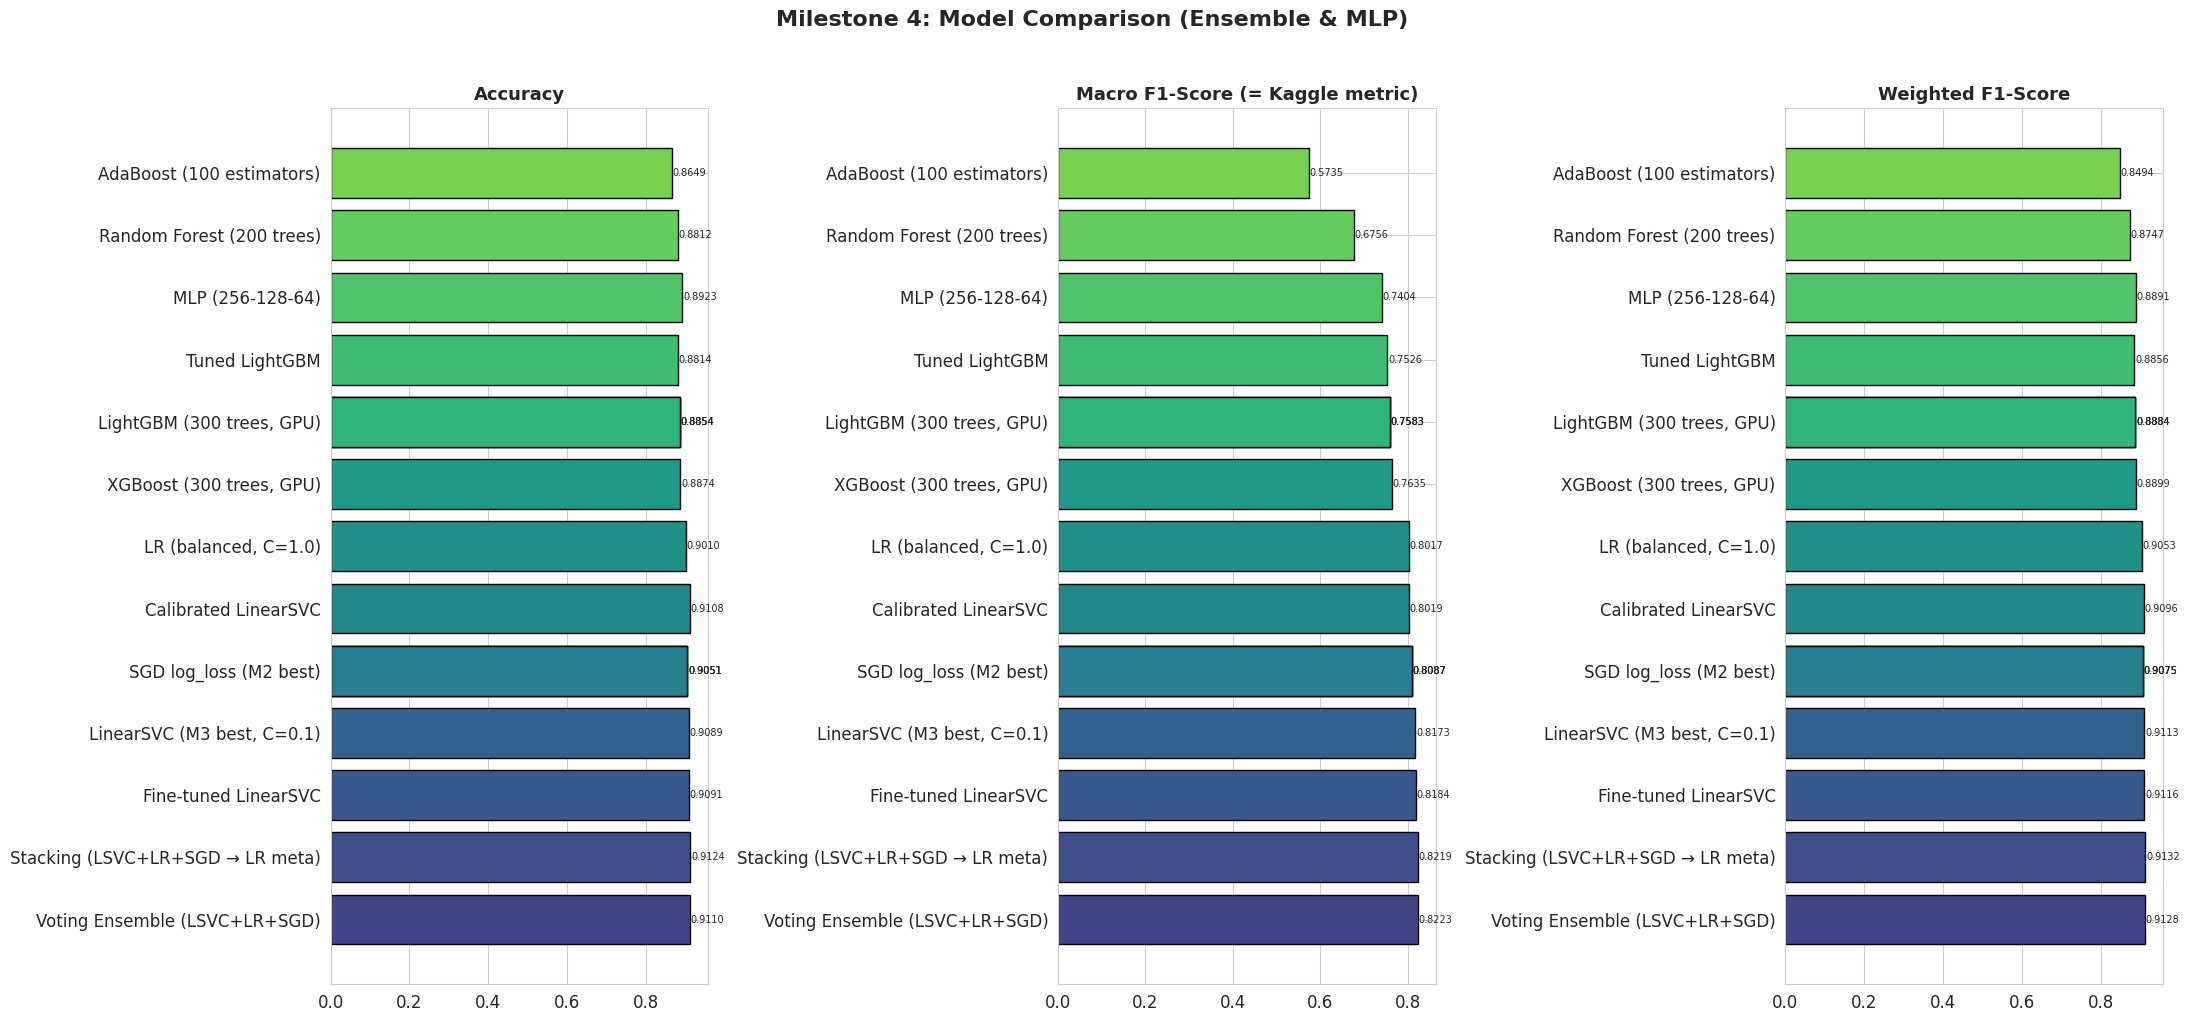

In [41]:
results_df = pd.DataFrame(all_results)
results_df = results_df.sort_values("macro_f1", ascending=False).reset_index(drop=True)

print("\n" + "=" * 85)
print("  COMPLETE MODEL COMPARISON — Milestone 4 (sorted by Macro F1 = Kaggle metric)")
print("=" * 85)
print(results_df.to_string(index=False))

# %%
# Visualization
fig, axes = plt.subplots(1, 3, figsize=(22, 10))
metrics = ["accuracy", "macro_f1", "weighted_f1"]
titles  = ["Accuracy", "Macro F1-Score (= Kaggle metric)", "Weighted F1-Score"]
colors_bar = plt.cm.viridis(np.linspace(0.2, 0.8, len(results_df)))

for idx, (metric, title) in enumerate(zip(metrics, titles)):
    bars = axes[idx].barh(results_df["name"], results_df[metric],
                          color=colors_bar, edgecolor="black")
    axes[idx].set_title(title, fontsize=13, fontweight="bold")
    for bar, val in zip(bars, results_df[metric]):
        axes[idx].text(val + 0.002, bar.get_y() + bar.get_height()/2,
                      f"{val:.4f}", va="center", fontsize=7)

plt.suptitle("Milestone 4: Model Comparison (Ensemble & MLP)",
             fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


## 19. Confusion Matrices — Top Models


In [42]:
# Identify top models
top_results = results_df.head(4)
print("Top 4 models for confusion matrices:")
for _, row in top_results.iterrows():
    print(f"  {row['name']} → Macro F1: {row['macro_f1']:.4f}")


Top 4 models for confusion matrices:
  Voting Ensemble (LSVC+LR+SGD) → Macro F1: 0.8223
  Stacking (LSVC+LR+SGD → LR meta) → Macro F1: 0.8219
  Fine-tuned LinearSVC → Macro F1: 0.8184
  LinearSVC (M3 best, C=0.1) → Macro F1: 0.8173


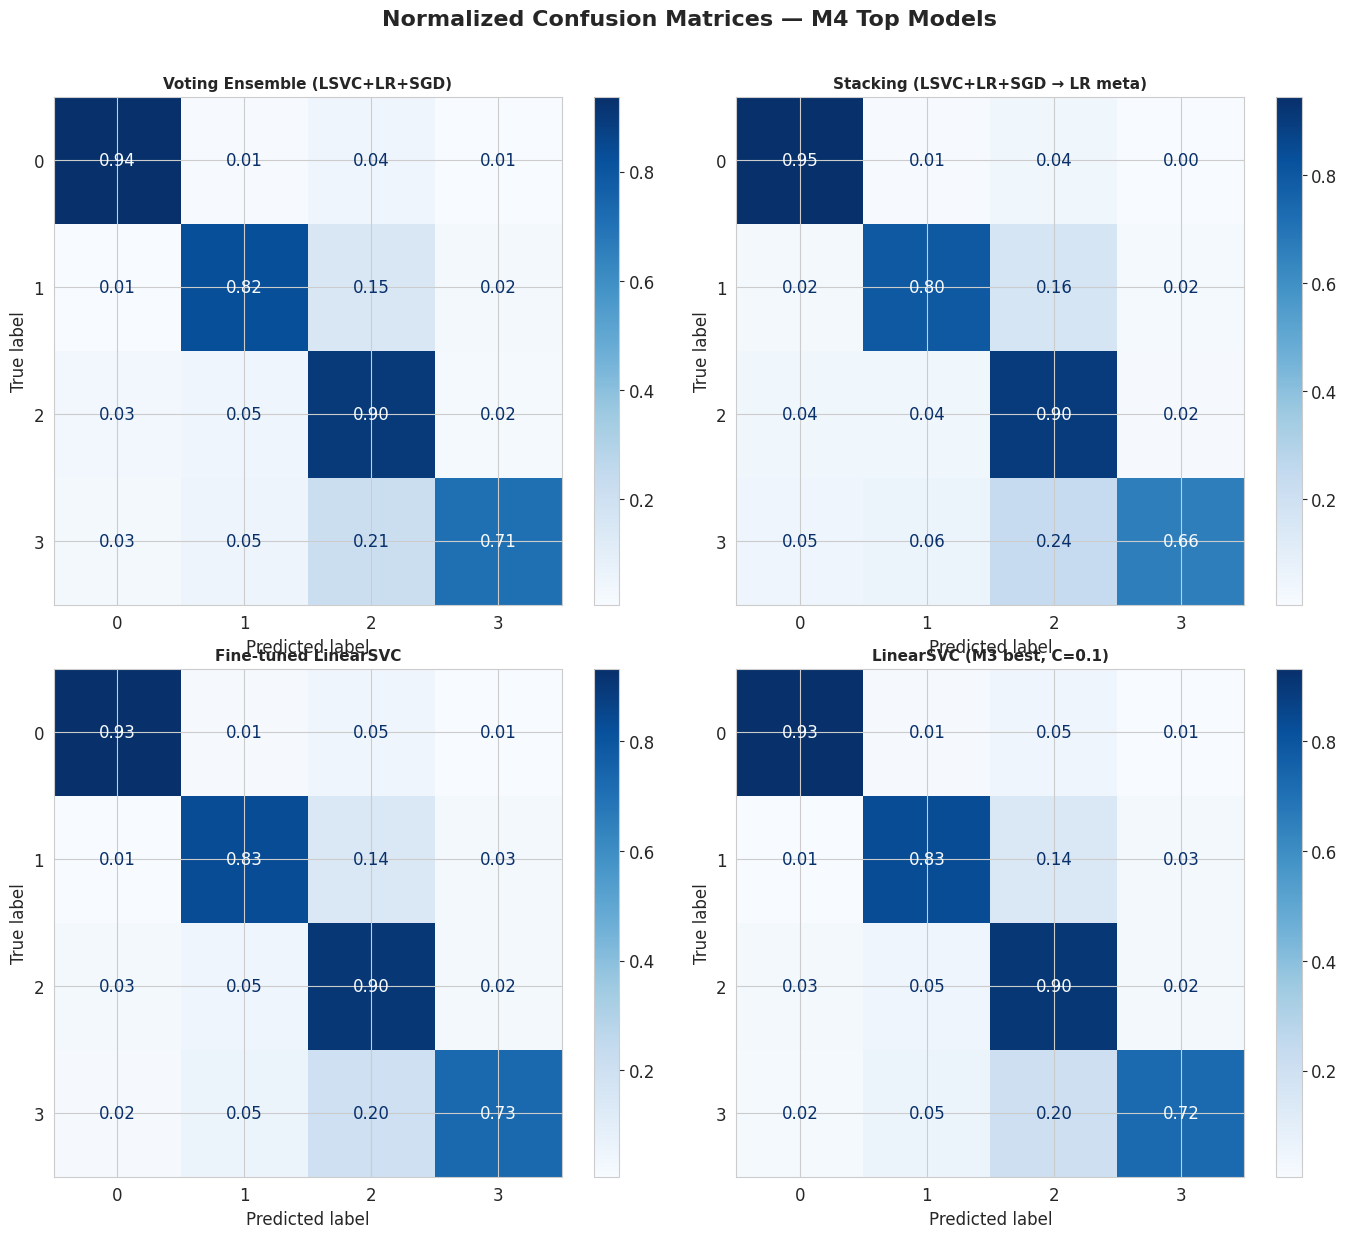

In [43]:
# Map model names to prediction functions
model_pred_map = {}

# LinearSVC predictions
model_pred_map["LinearSVC (M3 best, C=0.1)"] = lsvc_best.predict(X_vl)
model_pred_map["Fine-tuned LinearSVC"] = grid_lsvc_fine.predict(X_vl)
model_pred_map["Calibrated LinearSVC"] = cal_lsvc.predict(X_vl)
model_pred_map["LR (balanced, C=1.0)"] = lr.predict(X_vl)
model_pred_map["SGD log_loss (M2 best)"] = sgd.predict(X_vl)
model_pred_map["Voting Ensemble (LSVC+LR+SGD)"] = voting_clf.predict(X_vl)
model_pred_map["Stacking (LSVC+LR+SGD → LR meta)"] = stacking_clf.predict(X_vl)
model_pred_map["Random Forest (200 trees)"] = rf.predict(X_vl_d)
model_pred_map["AdaBoost (100 estimators)"] = ada.predict(X_vl_d)
# model_pred_map["GradientBoosting (200 trees)"] = gb.predict(X_vl_d)  # Commented out
model_pred_map["MLP (256-128-64)"] = mlp.predict(X_vl_d)
if HAS_XGB:
    model_pred_map["XGBoost (300 trees, balanced)"] = xgb_clf.predict(X_vl_d)
if HAS_LGB:
    model_pred_map["LightGBM (300 trees, balanced)"] = lgb_clf.predict(X_vl_d)

# Plot top 4
top_names = top_results["name"].tolist()
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
for idx, name in enumerate(top_names):
    ax = axes[idx // 2][idx % 2]
    if name in model_pred_map:
        preds = model_pred_map[name]
        cm = confusion_matrix(y_vl, preds, normalize="true")
        ConfusionMatrixDisplay(cm, display_labels=[0, 1, 2, 3]).plot(
            ax=ax, cmap="Blues", values_format=".2f")
        ax.set_title(name, fontsize=11, fontweight="bold")
    else:
        ax.set_title(f"{name} (N/A)", fontsize=11)
        ax.axis("off")

plt.suptitle("Normalized Confusion Matrices — M4 Top Models",
             fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

## 20. Generate Submissions

In [44]:
# ────────────────────────────────────────────────────────────
# Best model selection (by Macro F1 = Kaggle metric)
# ────────────────────────────────────────────────────────────
best_idx = results_df["macro_f1"].idxmax()
best_name = results_df.loc[best_idx, "name"]
best_f1   = results_df.loc[best_idx, "macro_f1"]
print(f"🏆 Best Model by Macro F1: {best_name} (F1: {best_f1:.4f})")


🏆 Best Model by Macro F1: Voting Ensemble (LSVC+LR+SGD) (F1: 0.8223)


In [45]:
# ────────────────────────────────────────────────────────────
# RETRAIN BEST MODELS ON ALL DATA for final submission
# ────────────────────────────────────────────────────────────
# Models trained on 80% → good for evaluation
# For Kaggle submission → retrain on 100% data for maximum signal
print("\n🏆 Retraining top models on ALL data for submission...")

# Retrain LinearSVC on all data
print("⏳ Retraining LinearSVC on all data...")
lsvc_final = LinearSVC(C=0.1, class_weight="balanced", max_iter=5000, random_state=42)
lsvc_final.fit(X_all, y)

# Retrain Fine-tuned LinearSVC on all data
print("⏳ Retraining Fine-tuned LinearSVC on all data...")
best_C = grid_lsvc_fine.best_params_["C"]
lsvc_fine_final = LinearSVC(C=best_C, class_weight="balanced", max_iter=5000, random_state=42)
lsvc_fine_final.fit(X_all, y)

# Retrain LR on all data
print("⏳ Retraining LR on all data...")
lr_final = LogisticRegression(C=1.0, solver="lbfgs", max_iter=3000,
                              class_weight="balanced", n_jobs=-1, random_state=42)
lr_final.fit(X_all, y)

# Retrain SGD on all data
print("⏳ Retraining SGD on all data...")
sgd_final = SGDClassifier(loss="log_loss", alpha=1e-05, penalty="l2",
                          learning_rate="optimal", eta0=0.1, max_iter=3000,
                          class_weight="balanced", n_jobs=-1, random_state=42)
sgd_final.fit(X_all, y)

# Retrain Calibrated LinearSVC on all data
print("⏳ Retraining Calibrated LinearSVC on all data...")
cal_lsvc_final = CalibratedClassifierCV(
    LinearSVC(C=0.1, class_weight="balanced", max_iter=5000, random_state=42),
    cv=3, method="sigmoid"
)
cal_lsvc_final.fit(X_all, y)

# Retrain Stacking on all data
print("⏳ Retraining Stacking Ensemble on all data...")
stacking_final = StackingClassifier(
    estimators=[
        ("cal_lsvc", CalibratedClassifierCV(
            LinearSVC(C=0.1, class_weight="balanced", max_iter=5000, random_state=42),
            cv=3, method="sigmoid")),
        ("lr", LogisticRegression(C=1.0, solver="lbfgs", max_iter=3000,
                                  class_weight="balanced", n_jobs=-1, random_state=42)),
        ("sgd", SGDClassifier(loss="log_loss", alpha=1e-05, penalty="l2",
                              class_weight="balanced", max_iter=3000,
                              n_jobs=-1, random_state=42)),
    ],
    final_estimator=LogisticRegression(C=1.0, max_iter=3000, random_state=42),
    cv=3, n_jobs=-1
)
stacking_final.fit(X_all, y)

# Retrain Voting on all data
print("⏳ Retraining Voting Ensemble on all data...")
voting_final = VotingClassifier(
    estimators=[
        ("cal_lsvc", CalibratedClassifierCV(
            LinearSVC(C=0.1, class_weight="balanced", max_iter=5000, random_state=42),
            cv=3, method="sigmoid")),
        ("lr", LogisticRegression(C=1.0, solver="lbfgs", max_iter=3000,
                                  class_weight="balanced", n_jobs=-1, random_state=42)),
        ("sgd", SGDClassifier(loss="log_loss", alpha=1e-05, penalty="l2",
                              class_weight="balanced", max_iter=3000,
                              n_jobs=-1, random_state=42)),
    ],
    voting="soft", n_jobs=-1
)
voting_final.fit(X_all, y)

# Retrain LightGBM with best params on all data
if HAS_LGB:
    print("⏳ Retraining Tuned LightGBM on all data...")
    best_lgb_params = rcv_lgb.best_params_
    lgb_final = lgb.LGBMClassifier(
        **best_lgb_params,
        class_weight="balanced",
        device=LGB_DEVICE,         # GPU if available, else CPU
        n_jobs=-1, random_state=42, verbose=-1
    )
    lgb_final.fit(X_dense_train, y)

print("✅ All models retrained on 100% data!")



🏆 Retraining top models on ALL data for submission...
⏳ Retraining LinearSVC on all data...
⏳ Retraining Fine-tuned LinearSVC on all data...
⏳ Retraining LR on all data...
⏳ Retraining SGD on all data...
⏳ Retraining Calibrated LinearSVC on all data...
⏳ Retraining Stacking Ensemble on all data...
⏳ Retraining Voting Ensemble on all data...
⏳ Retraining Tuned LightGBM on all data...
✅ All models retrained on 100% data!


In [46]:
# ────────────────────────────────────────────────────────────
# Generate submissions using RETRAINED models (100% data)
# ────────────────────────────────────────────────────────────
print("\n📋 Generating submission files (retrained on all data)...")

submission_models = {
    "linearsvc":         (lsvc_final,      X_test_all),
    "finetuned_lsvc":    (lsvc_fine_final,  X_test_all),
    "calibrated_lsvc":   (cal_lsvc_final,   X_test_all),
    "lr_balanced":       (lr_final,         X_test_all),
    "sgd_logloss":       (sgd_final,        X_test_all),
    "voting_ensemble":   (voting_final,     X_test_all),
    "stacking_ensemble": (stacking_final,   X_test_all),
}

if HAS_LGB:
    submission_models["tuned_lightgbm"] = (lgb_final, X_dense_test)

for name, (model, test_data) in submission_models.items():
    preds = model.predict(test_data)
    sub = sample.copy()
    sub["label"] = preds
    fname = f"submission_{name}.csv"
    sub.to_csv(fname, index=False)
    dist = dict(zip(*np.unique(preds, return_counts=True)))
    print(f"  ✅ {fname} | Distribution: {dist}")

# Main submission = Stacking (most consistent on Kaggle)
print("\n🏆 Main submission = Stacking Ensemble (most consistent)")
submission = sample.copy()
submission["label"] = stacking_final.predict(X_test_all)
submission.to_csv("submission.csv", index=False)
print(f"   Distribution: {dict(zip(*np.unique(submission['label'].values, return_counts=True)))}")



📋 Generating submission files (retrained on all data)...
  ✅ submission_linearsvc.csv | Distribution: {np.int64(0): np.int64(55839), np.int64(1): np.int64(9170), np.int64(2): np.int64(33448), np.int64(3): np.int64(3543)}
  ✅ submission_finetuned_lsvc.csv | Distribution: {np.int64(0): np.int64(55886), np.int64(1): np.int64(9178), np.int64(2): np.int64(33382), np.int64(3): np.int64(3554)}
  ✅ submission_calibrated_lsvc.csv | Distribution: {np.int64(0): np.int64(57310), np.int64(1): np.int64(7539), np.int64(2): np.int64(35312), np.int64(3): np.int64(1839)}
  ✅ submission_lr_balanced.csv | Distribution: {np.int64(0): np.int64(55815), np.int64(1): np.int64(10009), np.int64(2): np.int64(31719), np.int64(3): np.int64(4457)}
  ✅ submission_sgd_logloss.csv | Distribution: {np.int64(0): np.int64(56261), np.int64(1): np.int64(9304), np.int64(2): np.int64(32770), np.int64(3): np.int64(3665)}
  ✅ submission_voting_ensemble.csv | Distribution: {np.int64(0): np.int64(56404), np.int64(1): np.int64(90

# ---
# ## 21. Milestone 4 Summary

# ### Models Trained:
# | # | Model | Type | Notes |
# |---|-------|------|-------|
# | 1 | LinearSVC | Linear SVM | M3 champion, C=0.1, balanced |
# | 2 | Calibrated LinearSVC | Calibrated SVM | Adds probability output for ensembles |
# | 3 | Random Forest | Bagging | 200 trees on SVD features |
# | 4 | AdaBoost | Boosting | Sequential weak learner combination |
# | 5 | GradientBoosting | Boosting | Sklearn's gradient boosting |
# | 6 | XGBoost | Boosting | Optimized gradient boosting (if available) |
# | 7 | LightGBM | Boosting | Microsoft's fast gradient boosting (if available) |
# | 8 | MLP | Neural Network | 256-128-64 architecture |
# | 9 | LR | Linear | Baseline from M2-M3 |
# | 10 | SGD | Stochastic | Best from M2 |
# | 11 | Voting Ensemble | Ensemble | Soft voting: LSVC + LR + SGD |
# | 12 | Stacking Ensemble | Ensemble | LSVC + LR + SGD → LR meta-learner |

# ### Key Improvements:
# - All tuning optimizes for **Macro F1** (the Kaggle metric)
# - Ensemble methods combine diverse model strengths
# - SVD + original features for tree-based models
# - Multiple submission files for Kaggle comparison

# ### All M4 Question Answers:
# Printed inline in Section 3 with `📌 M4 Q` markers.

# ---
# **Next:** Milestone 5 — End-to-End Refinement
